# NeuroAdapt — Step 2: HDF5 preprocessing & patient/volume-level splits
Kaggle-ready. **No re-normalization by default.** The dataset is already preprocessed into 2D HDF5 slices. Verify MRI and mask channel semantics against the dataset documentation before training.

In [1]:
import re, h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
print("PyTorch", torch.__version__)

PyTorch 2.11.0+cpu


## 1. Locate HDF5 slices and extract volume IDs

In [2]:
ROOT=Path("/kaggle/input")
paths=sorted(ROOT.rglob("volume_*_slice_*.h5"))
assert paths, "No HDF5 slices found: attach awsaf49/brats2020-training-data"
pattern=re.compile(r"^volume_(\d+)_slice_(\d+)\.h5$")
rows=[]
for p in paths:
    m=pattern.match(p.name)
    if m: rows.append((str(p),int(m.group(1)),int(m.group(2))))
manifest=pd.DataFrame(rows,columns=["path","volume_id","slice_id"])
print("Slices:",len(manifest),"Volumes:",manifest.volume_id.nunique())
display(manifest.head())

Slices: 57195 Volumes: 369


,path,volume_id,slice_id
0,/kaggle/input/datasets/awsaf49/brats2020-train...,100,0
1,/kaggle/input/datasets/awsaf49/brats2020-train...,100,1
2,/kaggle/input/datasets/awsaf49/brats2020-train...,100,10
3,/kaggle/input/datasets/awsaf49/brats2020-train...,100,100
4,/kaggle/input/datasets/awsaf49/brats2020-train...,100,101


## 2. Inspect image/mask shapes, values and overlap
This is a **sample-based** check, not a full dataset audit. Channel order must be independently verified.

In [3]:
rng=np.random.default_rng(42)
check_idx=rng.choice(len(manifest),size=min(150,len(manifest)),replace=False)
checks=[]
for i in check_idx:
    p=manifest.iloc[int(i)].path
    with h5py.File(p,"r") as f:
        x=f["image"][:]; y=f["mask"][:]
    checks.append(dict(path=Path(p).name,image_shape=str(x.shape),mask_shape=str(y.shape),finite=bool(np.isfinite(x).all()),image_mean=float(x.mean()),image_std=float(x.std()),mask_values=str(np.unique(y).tolist()),positive=bool(y.any())))
check_df=pd.DataFrame(checks)
display(check_df.describe(include="all").T)
assert check_df.finite.all(), "Non-finite image intensities found"
print("Check dataset card for modality order and mask channel mapping before training.")

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
path,150,150,volume_222_slice_11.h5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
image_shape,150,1,"(240, 240, 4)",150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mask_shape,150,1,"(240, 240, 3)",150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
finite,150,1,True,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
image_mean,150.0,NaN,NaN,NaN,-0.0,0.0,-0.0,-0.0,0.0,0.0,0.0
image_std,150.0,NaN,NaN,NaN,0.919107,0.272158,0.0,1.0,1.0,1.0,1.0
mask_values,150,2,[0],77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positive,150,2,False,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Check dataset card for modality order and mask channel mapping before training.


## 3. Split by volume ID (70% train / 15% validation / 15% test)
All slices of one volume remain in the same partition. If volume IDs do not uniquely identify patients, replace this grouping with actual patient IDs.

In [4]:
volume_ids=np.sort(manifest.volume_id.unique())
train_ids,temp_ids=train_test_split(volume_ids,test_size=.30,random_state=42)
val_ids,test_ids=train_test_split(temp_ids,test_size=.50,random_state=42)
parts={"train":set(train_ids),"val":set(val_ids),"test":set(test_ids)}
assert not (parts["train"]&parts["val"] or parts["train"]&parts["test"] or parts["val"]&parts["test"])
manifest["split"]=manifest.volume_id.map(lambda v: next(k for k,s in parts.items() if v in s))
display(manifest.groupby("split").agg(slices=("path","size"),volumes=("volume_id","nunique")))

,slices,volumes
split,,
test,8680,56
train,39990,258
val,8525,55


## 4. Torch Dataset
Returns `image: float32 [4,H,W]`, `mask: float32 [3,H,W]`. Optional modality dropout for training only. A separate availability vector is returned. No interpolation or Z-score applied.

In [5]:
class BraTSH5Dataset(Dataset):
    def __init__(self, dataframe, modality_dropout=0.0):
        self.paths=dataframe.path.tolist()
        self.modality_dropout=modality_dropout
    def __len__(self): return len(self.paths)
    def __getitem__(self,index):
        with h5py.File(self.paths[index],"r") as f:
            x=f["image"][:].astype(np.float32)
            y=f["mask"][:].astype(np.float32)
        if x.shape!=(240,240,4) or y.shape!=(240,240,3):
            raise ValueError(f"Unexpected shapes: {x.shape}, {y.shape}")
        if not np.isfinite(x).all(): raise ValueError("Non-finite image values")
        if not np.isin(y,[0,1]).all(): raise ValueError("Non-binary mask; inspect encoding")
        x=torch.from_numpy(np.ascontiguousarray(x.transpose(2,0,1)))
        y=torch.from_numpy(np.ascontiguousarray(y.transpose(2,0,1)))
        available=torch.ones(4,dtype=torch.float32)
        if self.modality_dropout>0 and torch.rand(())<self.modality_dropout:
            drop=int(torch.randint(0,4,()).item())
            x[drop]=0
            available[drop]=0
        return {"image":x,"mask":y,"availability":available,"path":self.paths[index]}

## 5. Validate a batch

In [6]:
train_ds=BraTSH5Dataset(manifest[manifest.split=="train"].reset_index(drop=True))
val_ds=BraTSH5Dataset(manifest[manifest.split=="val"].reset_index(drop=True))
test_ds=BraTSH5Dataset(manifest[manifest.split=="test"].reset_index(drop=True))
train_loader=DataLoader(train_ds,batch_size=4,shuffle=True,num_workers=2,pin_memory=torch.cuda.is_available())
batch=next(iter(train_loader))
print({k:(v.shape if torch.is_tensor(v) else len(v)) for k,v in batch.items()})
assert batch["image"].shape[1:]==(4,240,240)
assert batch["mask"].shape[1:]==(3,240,240)

{'image': torch.Size([4, 4, 240, 240]), 'mask': torch.Size([4, 3, 240, 240]), 'availability': torch.Size([4, 4]), 'path': 4}


## 6. Visual sanity check

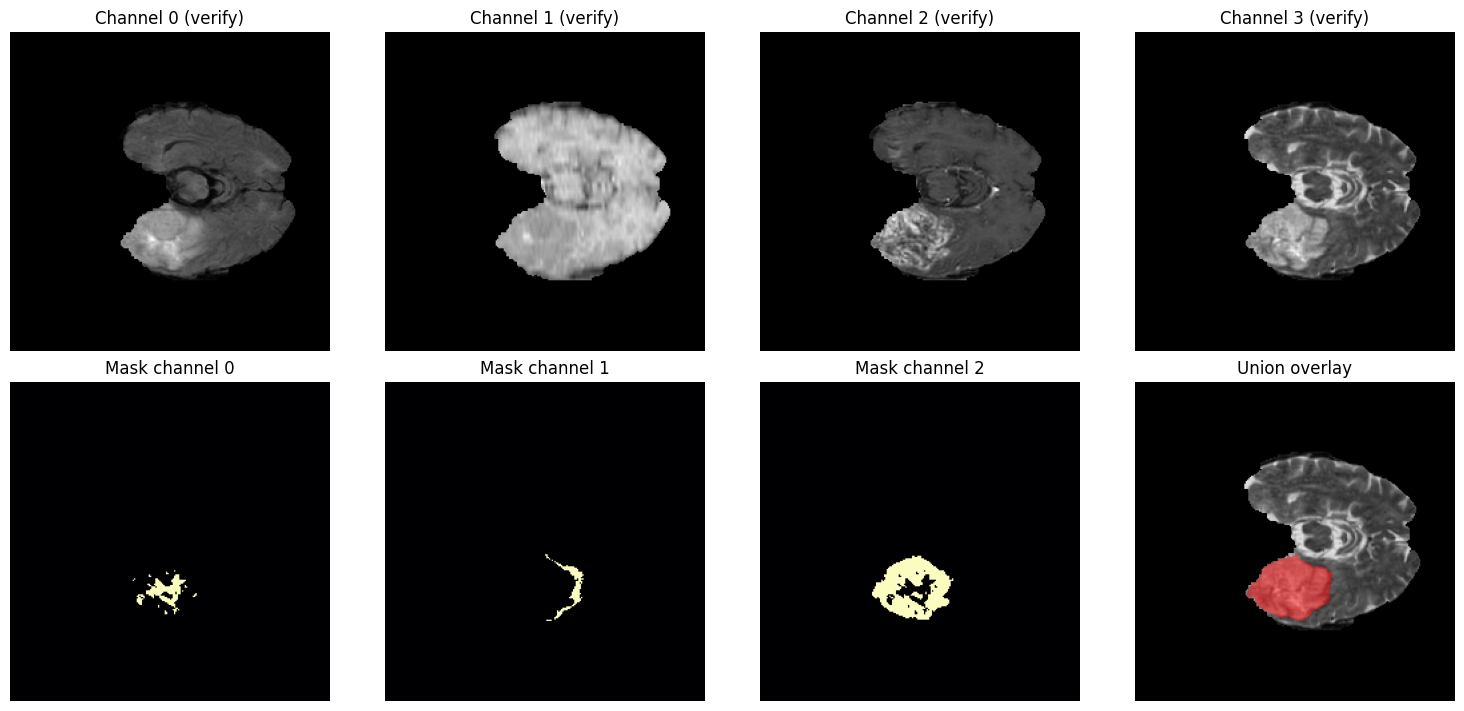

In [7]:
x=batch["image"][0].numpy(); y=batch["mask"][0].numpy()
fig,axs=plt.subplots(2,4,figsize=(15,7),constrained_layout=True)
for i,name in enumerate(["Channel 0 (verify)","Channel 1 (verify)","Channel 2 (verify)","Channel 3 (verify)"]):
    axs[0,i].imshow(x[i],cmap="gray");axs[0,i].set_title(name);axs[0,i].axis("off")
for i in range(3):
    axs[1,i].imshow(y[i],cmap="magma",vmin=0,vmax=1);axs[1,i].set_title(f"Mask channel {i}");axs[1,i].axis("off")
axs[1,3].imshow(x[3],cmap="gray");axs[1,3].imshow(np.ma.masked_where(~(y.max(0)>0),y.max(0)),cmap="autumn",alpha=.5);axs[1,3].set_title("Union overlay");axs[1,3].axis("off")
plt.show()

## 7. Save reproducible split manifests
Do not copy the entire dataset into `/kaggle/working`. Keep HDF5 paths in the manifests and mount the same Kaggle dataset in later notebooks.

In [8]:
OUT=Path("/kaggle/working/neuroadapt_preprocessing");OUT.mkdir(parents=True,exist_ok=True)
for split in ("train","val","test"):
    manifest[manifest.split==split].to_csv(OUT/f"{split}_manifest.csv",index=False)
check_df.to_csv(OUT/"sample_quality_checks.csv",index=False)
print("Saved to",OUT)

Saved to /kaggle/working/neuroadapt_preprocessing


## Before training
1. Confirm the four modality channel names and the three segmentation-channel definitions from the dataset source.
2. Check whether `volume_id` is a unique patient identifier.
3. Review more samples for shape, mask correctness and normalization consistency.
4. Begin with a **4-input / 3-output sigmoid** 2D U-Net baseline if masks are verified as multilabel.
5. Keep modality dropout **off for baseline** and enable it only in later robustness experiments.